# 03 — Exploratory Analysis & RFM Segmentation

**Owner:** Burgos Carrera, Maria de Los Angeles (Data Analyst)

EDA on churn and feature relationships, then true RFM segmentation.

In [1]:
# Make the src package importable whether or not it is pip-installed.
import sys, os
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
SRC = os.path.join(ROOT, 'src')
if SRC not in sys.path:
    sys.path.insert(0, SRC)
os.chdir(ROOT)
print('project root:', ROOT)

project root: C:\Users\johnm\Big_Data_Challenge_Project


In [2]:
import pandas as pd
from churn_project import exploratory_analysis as eda, rfm_analysis as rfm
from churn_project.config import CONFIG
df = pd.read_csv(CONFIG.path('clean_csv'))
print(eda.churn_overview(df))

{'total_customers': 10000, 'churned': 3771, 'retained': 6229, 'churn_rate': 0.3771, 'retained_rate': 0.6229, 'imbalance_ratio_majority_to_minority': 1.652}


## Numeric features by churn

In [3]:
eda.grouped_numeric_summary(df)

,feature,retained_mean,churned_mean,difference
0,days_since_last_purchase,8.786,300.617,291.831
1,account_age_days,256.747,214.362,-42.385
2,age,33.951,33.778,-0.172
3,total_orders,8.044,7.169,-0.875
4,total_spent_usd,315.860,306.214,-9.645
5,avg_order_value,210.491,205.467,-5.024
6,is_premium_member,0.140,0.150,0.010


## Generate and display EDA figures

churn_distribution


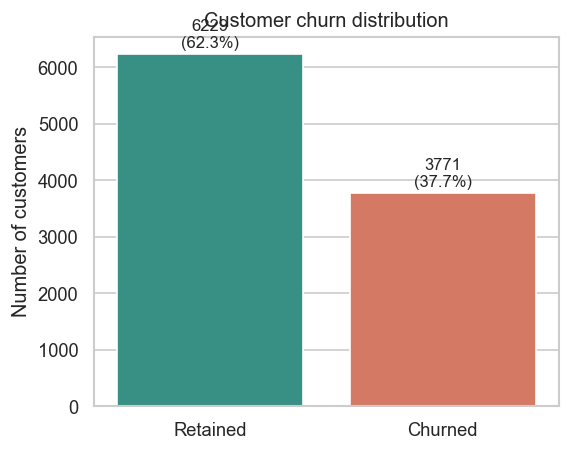

numeric_boxplots


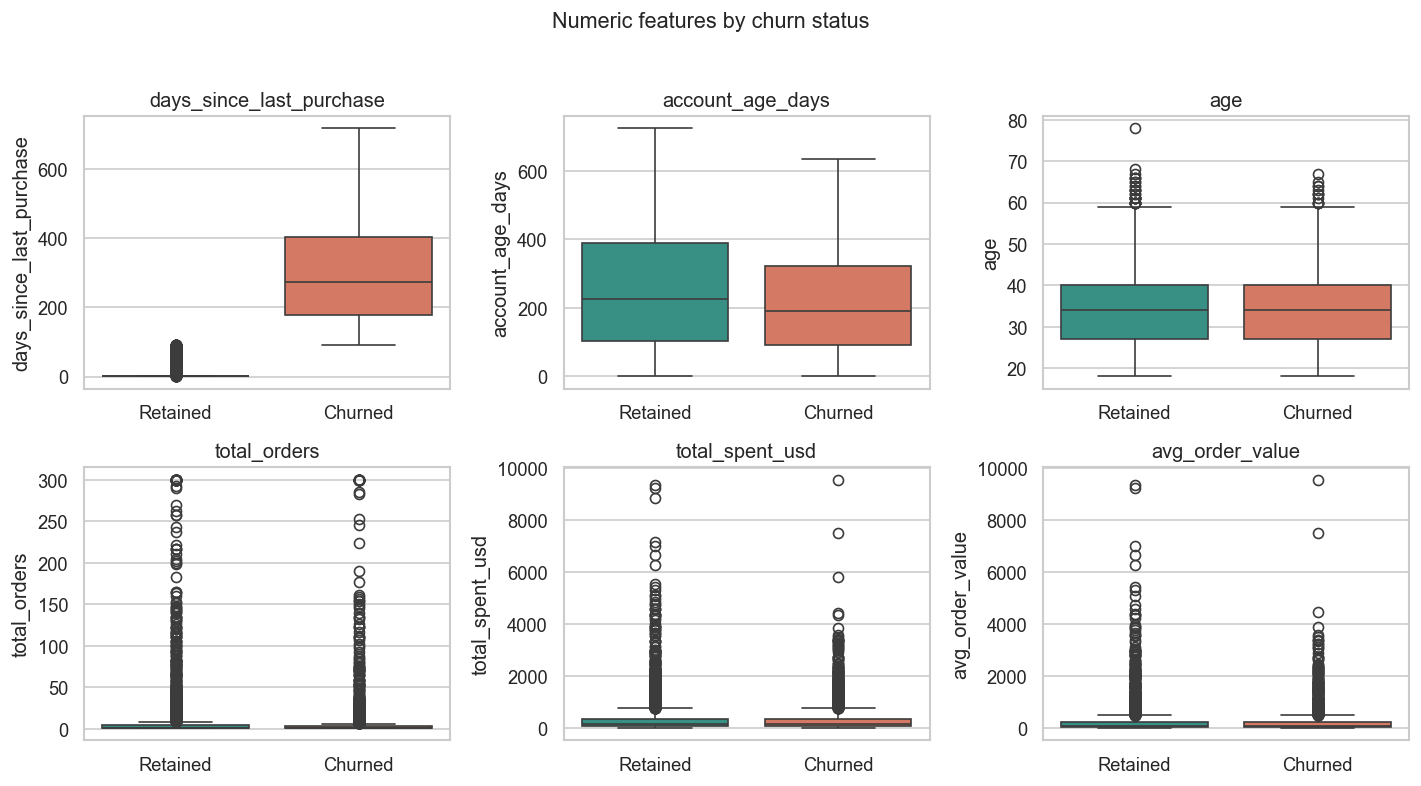

numeric_histograms


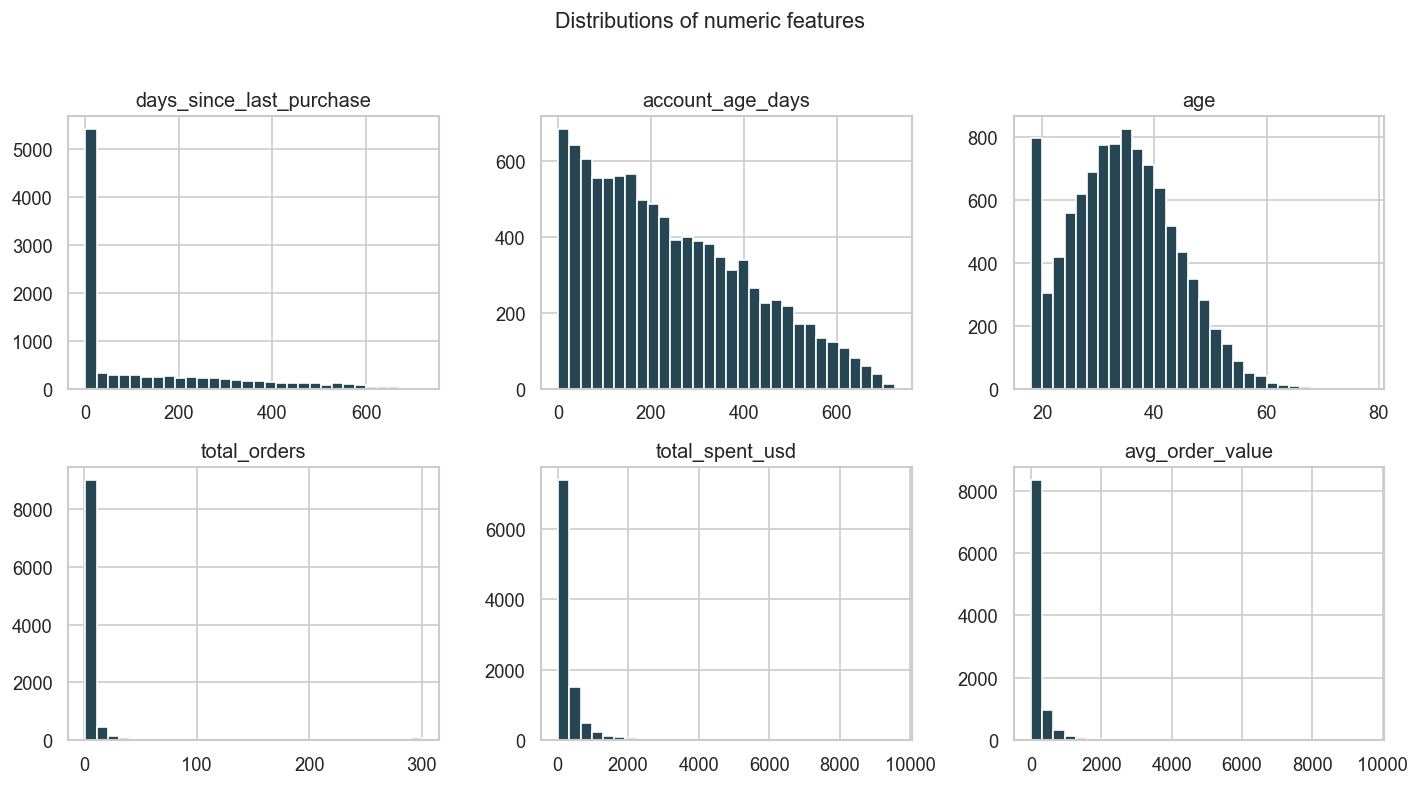

categorical_churn


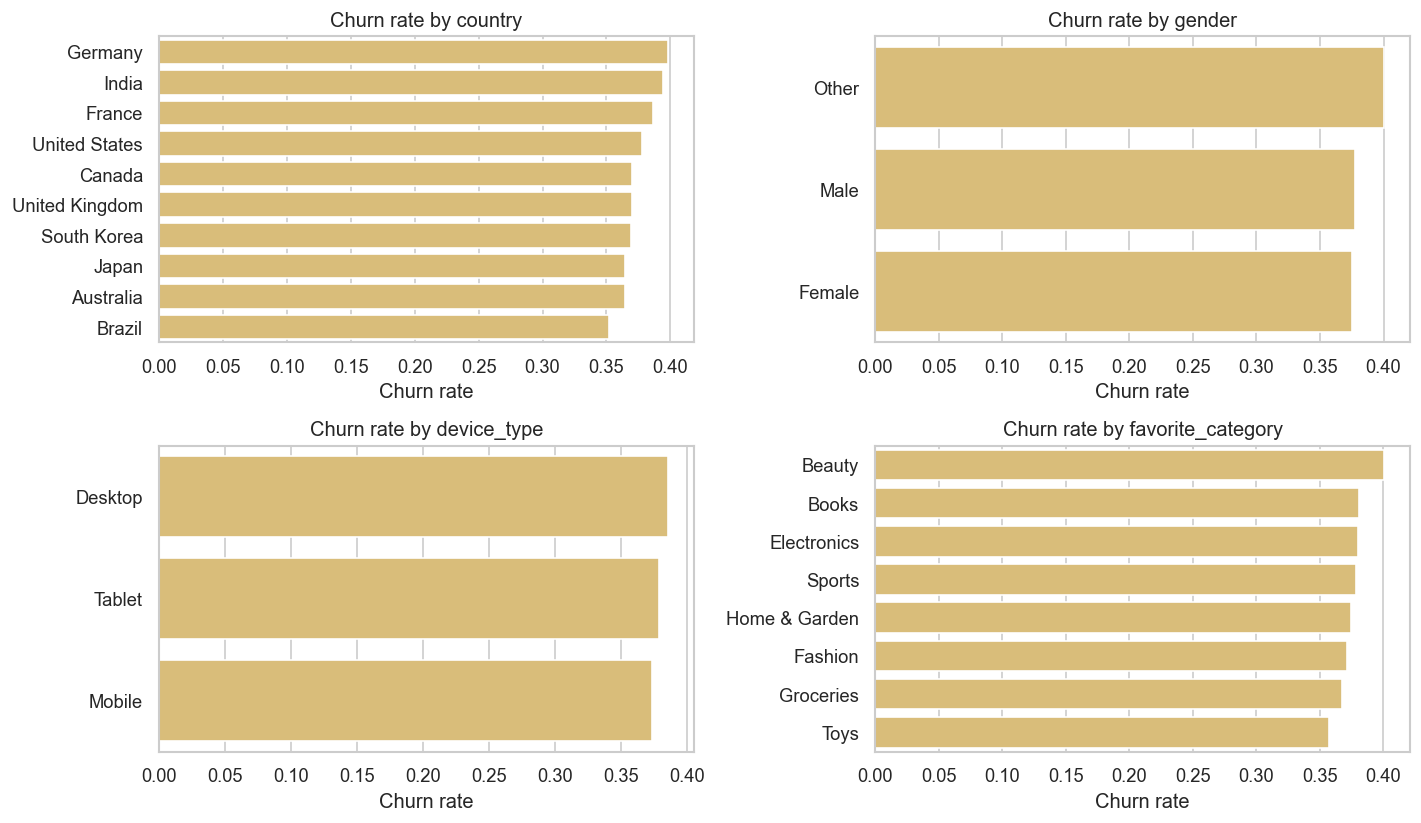

correlation_heatmap


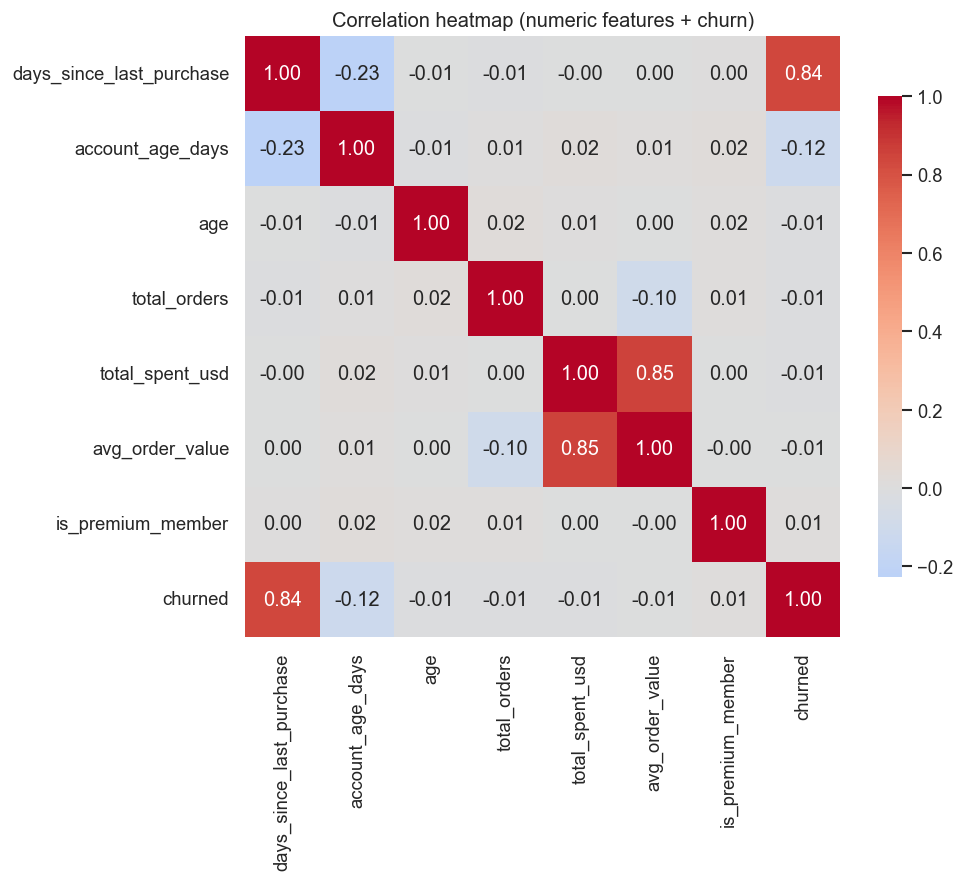

In [4]:
res = eda.run_full_eda(df)
from IPython.display import Image, display
for name, path in res['figures'].items():
    print(name); display(Image(path))

## RFM segmentation

In [5]:
rfm_df, meta = rfm.compute_rfm(df)
print('bins used:', meta['n_bins_used'])
rfm.segment_summary(rfm_df)

bins used: {'R': 5, 'F': 5, 'M': 5}


,segment,avg_recency_days,avg_frequency,avg_monetary_usd,n_customers,churn_rate,pct_customers
0,Needs Attention,288.5899,4.2509,220.0696,3041,0.9421,30.41
1,Loyal Customers,1.0000,6.0099,256.1674,2116,0.0000,21.16
2,About to Sleep,16.1140,7.8380,295.4396,2000,0.0000,20.00
3,Champions,1.0000,17.7824,655.6405,1048,0.0000,10.48
4,At Risk,286.2617,17.0125,608.8452,959,0.9447,9.59
5,Potential Loyalists,1.0000,1.0359,58.6937,836,0.0000,8.36


**Findings:** churn is explained almost entirely by recency. 'Needs Attention' and 'At Risk' segments carry ~94% churn; recent segments ~0%.